# Tugas 1 - Klasifikasi Jamur dengan Naive Bayes

| Nama | NRP |
|------|-----|
|Rasya Gonawi| 5054251032|

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Mushroom Dataset dari UCI Machine Learning Repository.

Dataset dapat diakses melalui:
- https://www.kaggle.com/datasets/uciml/mushroom-classification

Untuk metadata / penjelasan mengenai dataset bisa mengakses link berikut:
- https://archive.ics.uci.edu/dataset/73/mushroom

Tujuan utama dari tugas ini adalah membangun dan membandingkan tiga varian Naive Bayes, yaitu Categorical NB, Bernoulli NB, dan Multinomial NB, untuk mengklasifikasikan apakah suatu jamur dapat dimakan (edible) atau beracun (poisonous).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan untuk masing-masing varian Naive Bayes.
3. Eksperimen Model
   - Bangun model Categorical NB, Bernoulli NB, dan Multinomial NB.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [7]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder
from sklearn.naive_bayes import CategoricalNB, BernoulliNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, roc_curve, roc_auc_score,
                             classification_report)

In [3]:
# Load dataset dan tampilkan beberapa baris pertama.
# Semua nilai pada dataset berupa single character yang merupakan kode singkatan dari kategori.
# Contoh: pada kolom class, e = edible dan p = poisonous.

df = pd.read_csv('data/mushrooms.csv')

df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [12]:
# Tampilkan informasi dasar dataset: jumlah baris dan kolom, tipe data, dan jumlah missing value.
# Perhatikan kolom stalk-root yang memiliki nilai '?' sebagai representasi missing value.
df.info()

print((df['stalk-root'] == '?').sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

berarti missing value nya cuma berpusat di satu fitur saja yaitu stalk-root

In [15]:
# Tampilkan jumlah nilai unik pada setiap fitur.
# Perhatikan variasi jumlah kategori antar fitur, misalnya veil-type hanya punya 1 nilai unik.
df.nunique()

class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20712\2454544236.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='class', palette='Set2')


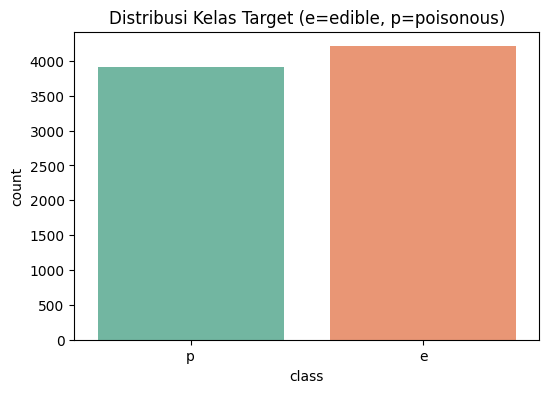

In [16]:
# Tampilkan distribusi kelas target (class) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='class', palette='Set2')
plt.title('Distribusi Kelas Target (e=edible, p=poisonous)')
plt.show()

bisa di bilang balance 

In [19]:
df.duplicated().sum()

np.int64(0)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

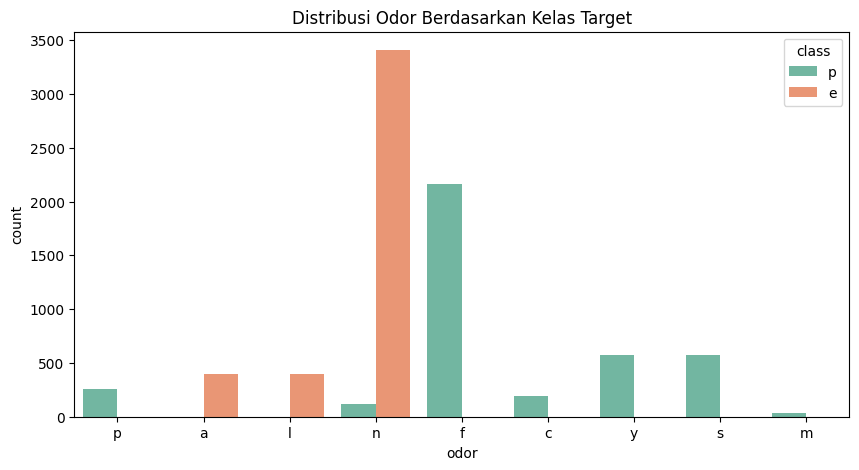

In [17]:
#melihat hubungan odor dengan class
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='odor', hue='class', palette='Set2')
plt.title('Distribusi Odor Berdasarkan Kelas Target')
plt.show()


disini hubungan antara odor(bau) dengan kelas cukup menarik, class yang aman cenderung tidak berbau, atau berbau almond dan manis, sedangkan yang poison itu memiliki bau yang cukup menyengat, contohnya f = foul

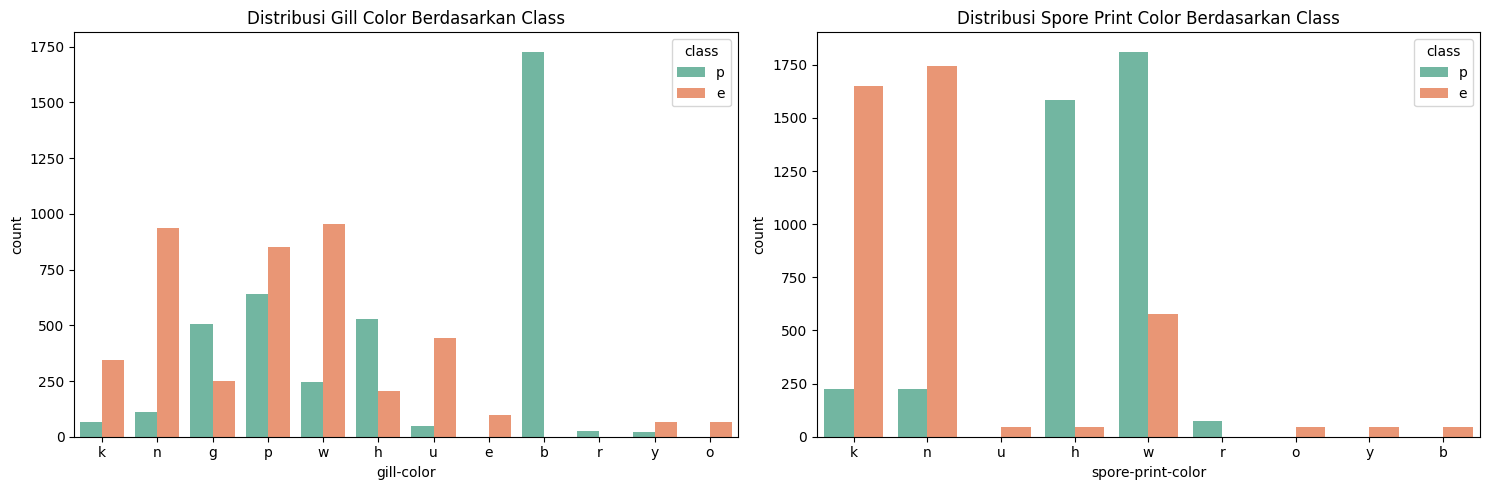

In [ ]:
#Distribusi  Gill Color & Spore Print Color
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Gill Color
sns.countplot(data=df, x='gill-color', hue='class', palette='Set2', ax=axes[0])
axes[0].set_title('Distribusi Gill Color Berdasarkan Class')

# Plot Spore Print Color 
sns.countplot(data=df, x='spore-print-color', hue='class', palette='Set2', ax=axes[1])
axes[1].set_title('Distribusi Spore Print Color Berdasarkan Class')

plt.tight_layout()
plt.show()
# Insight: Fitur gill-color 'b' (buff) dan spore-print-color 'h' (chocolate) sangat didominasi oleh jamur beracun.

# 2. Preprocessing

Karena semua fitur bertipe kategorikal, setiap varian Naive Bayes membutuhkan representasi data yang berbeda:

| Model | Representasi yang dibutuhkan | Preprocessing |
|---|---|---|
| Categorical NB | Integer per kategori | OrdinalEncoder |
| Bernoulli NB | Binary 0/1 per kategori | LabelBinarizer / OneHotEncoder |
| Multinomial NB | Count / frekuensi non-negatif | OneHotEncoder |

In [22]:
# Tangani missing value pada kolom stalk-root (nilai '?').
# Pilih strategi yang sesuai: drop baris, ganti dengan modus, atau jadikan kategori tersendiri.
# Karena '?' pada stalk-root cukup banyak (2480 baris, sekitar 30%),
# kita akan memperlakukannya sebagai kategori tersendiri alih-alih menghapus barisnya.
df['stalk-root'] = df['stalk-root'].replace('?', 'missing')

In [26]:
# Periksa apakah ada fitur yang hanya memiliki satu nilai unik.
# Fitur seperti itu tidak memberikan informasi apapun dan sebaiknya di-drop.
# veil-type hanya memiliki 1 nilai unik ('p'), tidak memberikan informasi apapun
df.drop('veil-type', axis=1, inplace=True)

KeyError: "['veil-type'] not found in axis"

In [27]:
# Pisahkan fitur (X) dan target (y).
# Encode target: e = 0 (edible), p = 1 (poisonous).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
from sklearn.model_selection import train_test_split

X = df.drop('class', axis=1)
# Encode target: e = 0 (edible), p = 1 (poisonous)
y = df['class'].map({'e': 0, 'p': 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Ukuran data latih: {X_train.shape[0]} baris")
print(f"Ukuran data uji: {X_test.shape[0]} baris")

Ukuran data latih: 6499 baris
Ukuran data uji: 1625 baris


In [28]:
# Preprocessing untuk Categorical NB:
# Gunakan OrdinalEncoder untuk mengubah setiap kategori menjadi integer.
# Contoh: cap-shape b=0, c=1, f=2, k=3, s=4, x=5
# Fit hanya pada train set, transform pada train set dan test set.
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
# Fit dan transform pada train, transform pada test
X_train_cat = oe.fit_transform(X_train)
X_test_cat = oe.transform(X_test)

In [29]:
# Preprocessing untuk Bernoulli NB dan Multinomial NB:
# Gunakan OneHotEncoder untuk mengubah setiap kategori menjadi representasi binary.
# Hasilnya berupa matriks sparse dengan nilai 0 dan 1.
# Fit hanya pada train set, transform pada train set dan test set.
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# Fit dan transform pada train, transform pada test
X_train_ohe = ohe.fit_transform(X_train)
X_test_ohe = ohe.transform(X_test)

# 3. Eksperimen Model

## 3.1 Categorical Naive Bayes

CategoricalNB adalah varian yang paling sesuai untuk dataset ini karena semua fitur memang bertipe kategorikal. Model menghitung P(fitur=kategori | kelas) secara langsung untuk setiap kategori pada setiap fitur.

In [30]:
# Inisialisasi dan latih model CategoricalNB menggunakan train set hasil OrdinalEncoder.
from sklearn.naive_bayes import CategoricalNB

cat_nb = CategoricalNB()
cat_nb.fit(X_train_cat, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None
,min_categories,None


In [31]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_cat = cat_nb.predict(X_test_cat)
y_prob_cat = cat_nb.predict_proba(X_test_cat)[:, 1]

## 3.2 Bernoulli Naive Bayes

BernoulliNB bekerja pada representasi binary. Dengan OneHotEncoder, setiap kategori menjadi kolom tersendiri bernilai 0 atau 1, sehingga model memperlakukan setiap kategori sebagai fitur binary ada/tidak ada.

In [32]:
# Inisialisasi dan latih model BernoulliNB menggunakan train set hasil OneHotEncoder.
from sklearn.naive_bayes import BernoulliNB

ber_nb = BernoulliNB()
ber_nb.fit(X_train_ohe, y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [33]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_ber = ber_nb.predict(X_test_ohe)
y_prob_ber = ber_nb.predict_proba(X_test_ohe)[:, 1]

## 3.3 Multinomial Naive Bayes

MultinomialNB membutuhkan input non-negatif dan menginterpretasikannya sebagai frekuensi. Dengan OneHotEncoder yang menghasilkan nilai 0 dan 1, model dapat menerimanya sebagai counts meskipun secara semantik tiap nilai hanya menandakan ada/tidak ada kategori.

In [34]:
# Inisialisasi dan latih model MultinomialNB menggunakan train set hasil OneHotEncoder.
from sklearn.naive_bayes import MultinomialNB

mul_nb = MultinomialNB()
mul_nb.fit(X_train_ohe, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [35]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_mul = mul_nb.predict(X_test_ohe)
y_prob_mul = mul_nb.predict_proba(X_test_ohe)[:, 1]

# 4. Evaluasi Model

In [36]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

metrics_df = pd.DataFrame([
    get_metrics(y_test, y_pred_cat, 'Categorical NB'),
    get_metrics(y_test, y_pred_ber, 'Bernoulli NB'),
    get_metrics(y_test, y_pred_mul, 'Multinomial NB')
])

display(metrics_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Categorical NB,0.945846,0.990127,0.896552,0.941019
1,Bernoulli NB,0.932923,0.981429,0.877395,0.926500
2,Multinomial NB,0.945846,0.990127,0.896552,0.941019


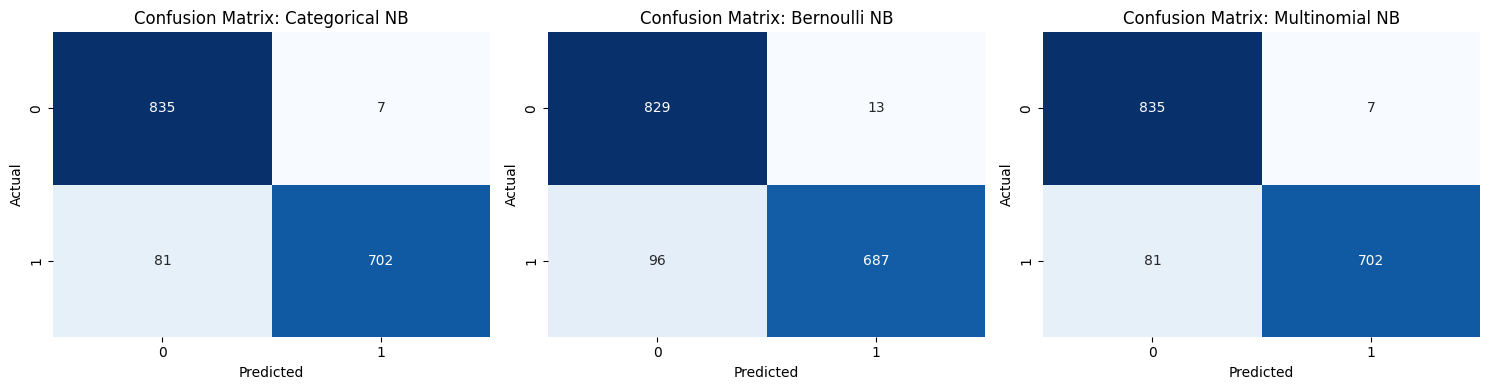

In [37]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun ketiganya dalam satu baris subplot.
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models_preds = [
    ('Categorical NB', y_pred_cat),
    ('Bernoulli NB', y_pred_ber),
    ('Multinomial NB', y_pred_mul)
]

for ax, (name, y_pred) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'Confusion Matrix: {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

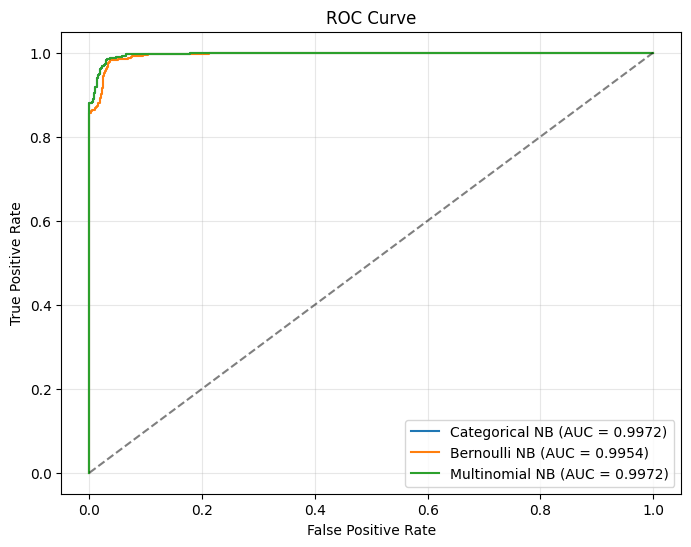

In [38]:
# Tampilkan ROC Curve ketiga model dalam satu plot beserta nilai AUC masing-masing.
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

models_probs = [
    ('Categorical NB', y_prob_cat),
    ('Bernoulli NB', y_prob_ber),
    ('Multinomial NB', y_prob_mul)
]

for name, y_prob in models_probs:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Analisis

disini dilakukan 2 teknik encoding untuk setiap modelnya

digunakan ordinal encoding untuk Categorical Naive Bayes, yang dimana ini mengubah setiap kategori menjadi 0.1.2. dst..

dan digunakan one hot encoding untu Bernoulli NB dan multinomial NB yang mengubah nilai kategori menjadi kolom binery (1 untuk ya, 0 untuk tidak)

disini model untuk kategorikal NB dan multinonial NB menghasilkan akurasi yang sama, yaitu 94.58 persen sedangkan bernoulli MB menghasilkan 93.29 persen

ini cukup menarik dikarenakan ini berkaitan dengan bagaimana cara setiap model bekerja, dan mengapa hasil dari bernoulli bisa berbeda dengan multinomial padahal menggunakan teknik encoding yang sama yaitu one hot encoding

Multinomial NB seharusnya menghitung seberapa sering sebuah "kata" muncul (frekuensi bernilai positif, seperti 1, 2, 3 kali). Namun, karena kita menggunakan One-Hot Encoding, nilai frekuensi yang masuk hanyalah 1 (jika kategori itu ada) atau 0 (jika tidak ada)

Dalam kasus di mana setiap baris observasi (setiap jamur) memiliki tepat satu kategori untuk setiap fitur (misal: satu bentuk topi, satu warna, satu bau), maka secara probabilitas matematis, Multinomial NB yang memproses data One-Hot (berisi deretan 0 dan satu angka 1 untuk tiap fitur) akan memiliki kalkulasi Likelihood  yang proporsionalnya identik dengan Categorical NB yang memproses data integer 

namun berbeda dengan bernoulli, Bernoulli menghitung dua hal, yaitu probabilitas fitur itu ada, DAN probabilitas fitur itu tidak ada (karena dia memecahnya jadi True/False per masing-masing One-Hot kolom). Itulah kenapa performa Bernoulli berbeda. Sedangkan, Multinomial NB tidak mempedulikan angka 0. dia hanya menghitung probabilitas saat angka frekuensinya = 1. Secara logika, ini jadi sama persis dengan Categorical NB yang menghitung probabilitas sebuah kategori terpilih.




# 6. Kesimpulan dan Saran

Categorical Naive Bayes adalah pilihan model terbaik dan paling direkomendasikan untuk tugas klasifikasi Mushroom ini. Meskipun akurasinya sama dengan Multinomial NB, dari sisi kecepatan komputasi dan manajemen memori, Categorical NB menang telak karena hanya perlu memproses sedikit kolom Ordinal dibandingkan puluhan kolom dari hasil transformasi One-Hot Encoding. saran kedepannya, tolong dataset nya menggunakan kategori yang lebih jelas karena cukup sulit untuk mengingat kategori disetiap fitur karena hanya berupa huruf